# Project 11：心脏病早期风险预测与现场交互

基于 **UCI Heart Disease（Cleveland）** 数据集和 `P11_01.pdf` 的分析方案，本 Notebook 完成：

1. 数据读取、缺失值处理与探索性数据分析（EDA）；
2. 逻辑回归、决策树、随机森林三种分类器的训练与比较；
3. Accuracy、Sensitivity、Specificity、F1、ROC-AUC 和交叉验证评估；
4. 特征重要性与逻辑回归系数解释；
5. **动态输入 13 项医学指标，选择模型与阈值，现场输出风险概率和分类结果。**

> 运行方式：保持本文件与 `heart+disease` 文件夹的相对位置不变，在 Jupyter 中选择 **Kernel → Restart & Run All**。最后一部分为交互预测面板。
>
> **免责声明：** 本模型仅用于数据科学教学，不能用于临床诊断或替代专业医疗建议。

## 1. 环境准备

所需包：`numpy`、`pandas`、`matplotlib`、`seaborn`、`scikit-learn`、`ipywidgets`。如本机缺少依赖，可在终端执行：

```bash
python -m pip install numpy pandas matplotlib seaborn scikit-learn ipywidgets notebook
```

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, HTML, Markdown

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score, recall_score, precision_score, f1_score,
    confusion_matrix, roc_auc_score, roc_curve, ConfusionMatrixDisplay
)

warnings.filterwarnings("ignore", category=UserWarning, module="matplotlib")
sns.set_theme(style="whitegrid")
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "Arial Unicode MS", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
RANDOM_STATE = 42
pd.set_option("display.max_columns", 30)

## 2. 读取数据与缺失值处理

原始文件有 303 行、14 列，其中 `ca` 和 `thal` 含 `?`。按照 PDF 的完整病例分析方案，将 `?` 读为缺失值并删除含缺失值的 6 行，最终使用 **297 条记录**。目标变量由原始的 0～4 级诊断转换为二分类：0 表示无心脏病，1～4 合并为 1（存在心脏病）。

In [2]:
columns = [
    "age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
    "thalach", "exang", "oldpeak", "slope", "ca", "thal", "target"
]
feature_names = columns[:-1]
continuous = ["age", "trestbps", "chol", "thalach", "oldpeak"]
categorical = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]

candidates = [
    Path.cwd() / "heart+disease" / "processed.cleveland.data",
    Path.cwd() / "processed.cleveland.data",
]
DATA_PATH = next((p for p in candidates if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("未找到 processed.cleveland.data，请确认 heart+disease 文件夹与本 Notebook 位于同一目录。")

raw = pd.read_csv(DATA_PATH, header=None, names=columns, na_values="?")
missing_summary = pd.DataFrame({
    "缺失数量": raw.isna().sum(),
    "缺失比例(%)": (raw.isna().mean() * 100).round(2)
})
print(f"数据文件：{DATA_PATH.resolve()}")
print(f"原始数据：{raw.shape[0]} 行 × {raw.shape[1]} 列")
display(missing_summary[missing_summary["缺失数量"] > 0])

df = raw.dropna().copy()
df["target"] = (df["target"] > 0).astype(int)
for col in categorical:
    df[col] = df[col].astype(int)

assert df.shape == (297, 14), "清洗后的数据形状与 PDF 不一致"
assert not df.isna().any().any(), "数据中仍有缺失值"
print(f"建模数据：{df.shape[0]} 行 × {df.shape[1]} 列；无缺失值")
display(df.head())

数据文件：D:\kimicode_cash\heart+disease\processed.cleveland.data
原始数据：303 行 × 14 列


,缺失数量,缺失比例(%)
ca,4,1.32
thal,2,0.66


建模数据：297 行 × 14 列；无缺失值


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1,1,145.0,233.0,1,2,150.0,0,2.3,3,0,6,0
1,67.0,1,4,160.0,286.0,0,2,108.0,1,1.5,2,3,3,1
2,67.0,1,4,120.0,229.0,0,2,129.0,1,2.6,2,2,7,1
3,37.0,1,3,130.0,250.0,0,0,187.0,0,3.5,3,0,3,0
4,41.0,0,2,130.0,204.0,0,2,172.0,0,1.4,1,0,3,0


## 3. 探索性数据分析（EDA）

目标类别略有不均衡，因此除 Accuracy 外，还需重点关注 **Sensitivity（患病者被识别出来的比例）** 和 **ROC-AUC**。

类别分布：


,样本数,比例(%)
无心脏病 (0),160,53.9
存在心脏病 (1),137,46.1


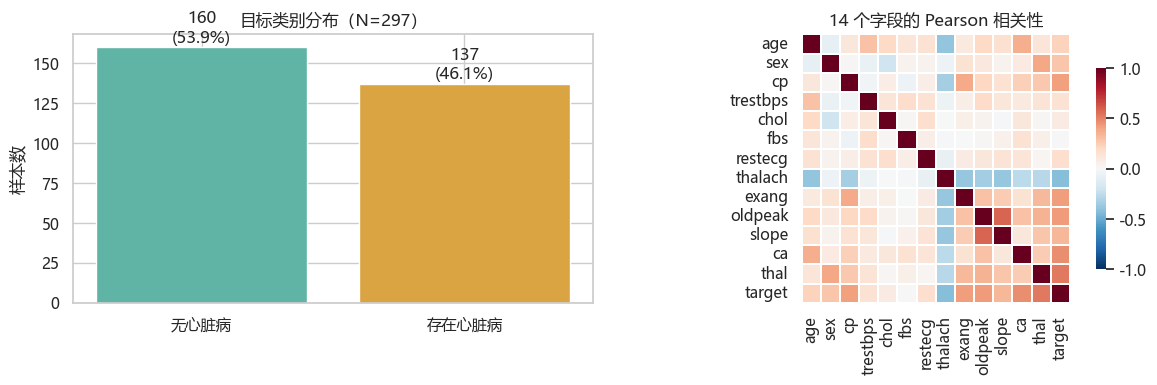

In [3]:
class_counts = df["target"].value_counts().sort_index()
print("类别分布：")
display(pd.DataFrame({
    "样本数": class_counts,
    "比例(%)": (class_counts / len(df) * 100).round(1)
}).rename(index={0: "无心脏病 (0)", 1: "存在心脏病 (1)"}))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(["无心脏病", "存在心脏病"], class_counts.values, color=["#5FB4A5", "#D9A441"])
axes[0].set_title("目标类别分布（N=297）")
axes[0].set_ylabel("样本数")
for i, value in enumerate(class_counts.values):
    axes[0].text(i, value + 3, f"{value}\n({value / len(df):.1%})", ha="center")

corr = df.corr()
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.3, cbar_kws={"shrink": 0.75}, ax=axes[1])
axes[1].set_title("14 个字段的 Pearson 相关性")
plt.tight_layout()
plt.show()

连续变量描述性统计：


,count,mean,std,min,25%,50%,75%,max,median,IQR
age,297.0,54.54,9.05,29.0,48.0,56.0,61.0,77.0,56.0,13.0
trestbps,297.0,131.69,17.76,94.0,120.0,130.0,140.0,200.0,130.0,20.0
chol,297.0,247.35,52.00,126.0,211.0,243.0,276.0,564.0,243.0,65.0
thalach,297.0,149.60,22.94,71.0,133.0,153.0,166.0,202.0,153.0,33.0
oldpeak,297.0,1.06,1.17,0.0,0.0,0.8,1.6,6.2,0.8,1.6


按目标分组的均值：


,age,trestbps,chol,thalach,oldpeak
target,,,,,
无心脏病,52.64,129.18,243.49,158.58,0.60
存在心脏病,56.76,134.64,251.85,139.11,1.59


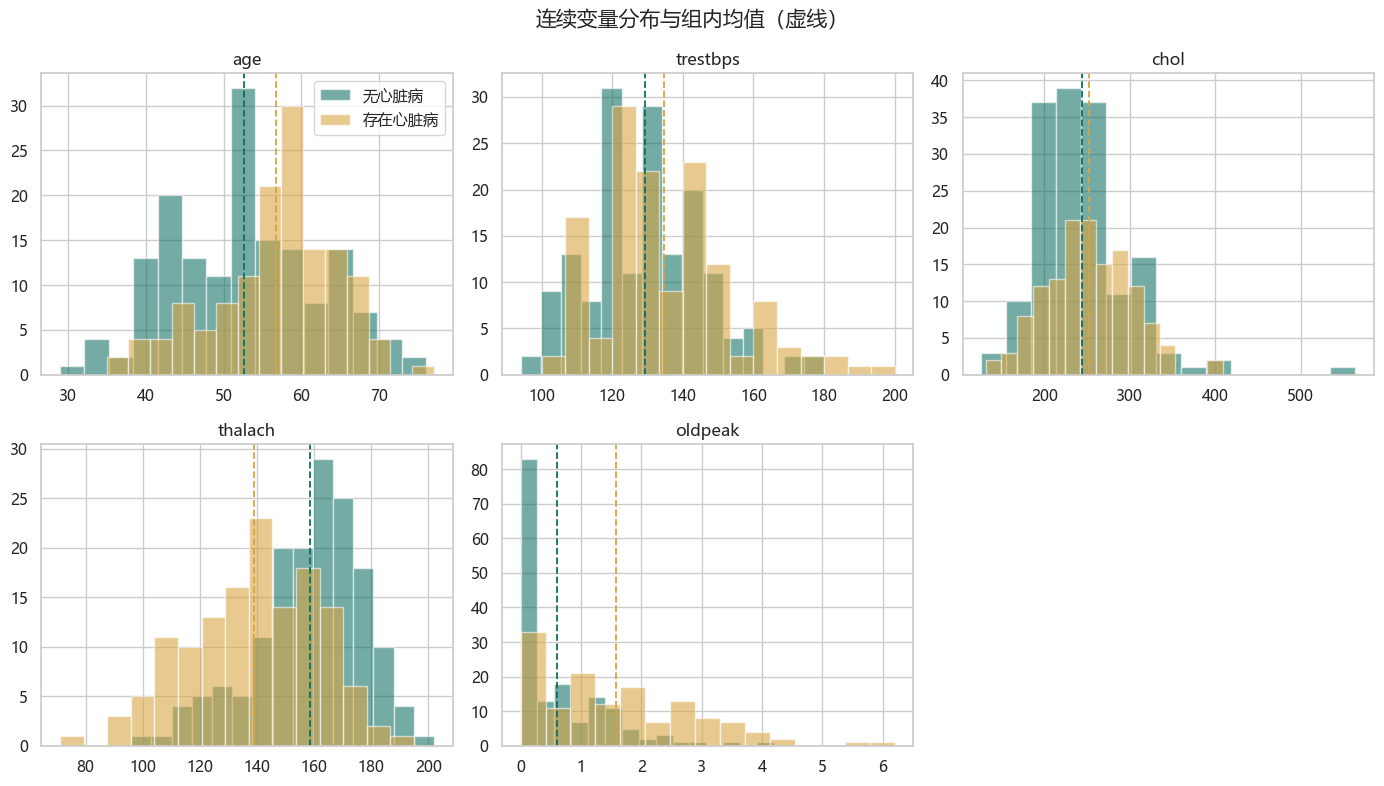

In [4]:
desc = df[continuous].describe().T
desc["median"] = df[continuous].median()
desc["IQR"] = desc["75%"] - desc["25%"]
print("连续变量描述性统计：")
display(desc.round(2))
print("按目标分组的均值：")
display(df.groupby("target")[continuous].mean().rename(index={0: "无心脏病", 1: "存在心脏病"}).round(2))

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, col in zip(axes.ravel(), continuous):
    for target, color, label in [(0, "#0F6E63", "无心脏病"), (1, "#D9A441", "存在心脏病")]:
        values = df.loc[df["target"] == target, col]
        ax.hist(values, bins=15, alpha=0.58, color=color, label=label, edgecolor="white")
        ax.axvline(values.mean(), color=color, linestyle="--", linewidth=1.3)
    ax.set_title(col)
axes.ravel()[-1].axis("off")
axes.ravel()[0].legend()
fig.suptitle("连续变量分布与组内均值（虚线）", fontsize=15)
plt.tight_layout()
plt.show()

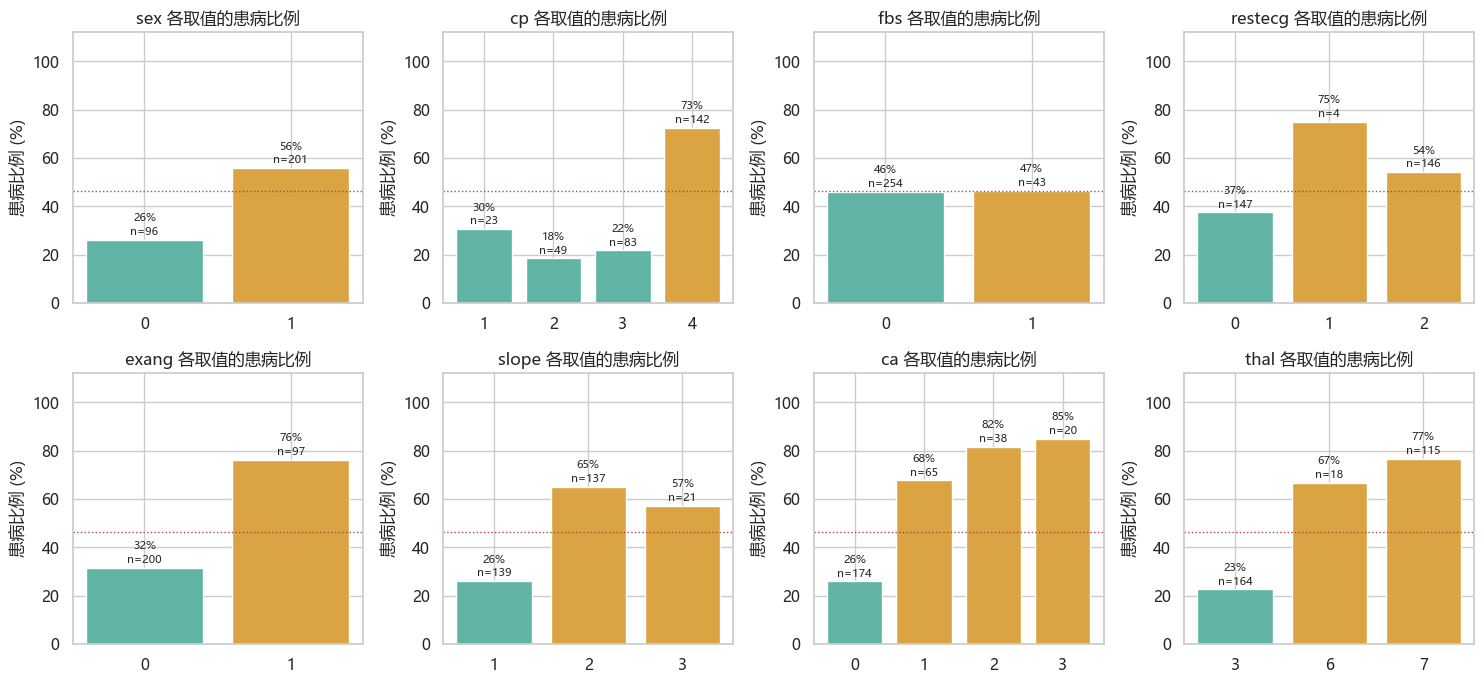

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(15, 7))
base_rate = df["target"].mean()
for ax, col in zip(axes.ravel(), categorical):
    rate = df.groupby(col)["target"].mean()
    counts = df.groupby(col).size()
    colors = ["#D9A441" if r >= base_rate else "#5FB4A5" for r in rate]
    bars = ax.bar(rate.index.astype(str), rate.values * 100, color=colors)
    for bar, r, n in zip(bars, rate, counts):
        ax.text(bar.get_x() + bar.get_width() / 2, r * 100 + 2,
                f"{r:.0%}\nn={n}", ha="center", fontsize=8)
    ax.axhline(base_rate * 100, color="#B0483E", linestyle=":", linewidth=1)
    ax.set_ylim(0, 112)
    ax.set_title(f"{col} 各取值的患病比例")
    ax.set_ylabel("患病比例 (%)")
plt.tight_layout()
plt.show()

## 4. 模型训练、概率校准与多指标评估

沿用 75%/25% 分层划分和 `random_state=42`。02 版按照修改建议书进行两项结构优化：

1. 三个基础模型均使用 `CalibratedClassifierCV(method="sigmoid", cv=5)` 做 **Platt 概率校准**，校准器只在训练集内部通过交叉验证学习，避免用同一批数据拟合和校准；
2. 决策树增加 `min_samples_leaf=10`，减少小样本纯叶节点造成的 0%/100% 极端输出。

除 Accuracy、Sensitivity、Specificity、F1 和 ROC-AUC 外，新增：

- **Brier 分数**：预测概率与真实标签的均方误差，越小越好；
- **LogLoss**：对错误且自信的概率惩罚更强，越小越好。

为直观判断优化效果，后续同时保留**未校准基线模型**与**校准后模型**的概率质量对比。测试集只有 75 条，校准曲线仍可能波动，应结合多个指标解释。

In [6]:
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import brier_score_loss, log_loss

X = df[feature_names]
y = df["target"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)

base_models = {
    "逻辑回归": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
    ]),
    "决策树": DecisionTreeClassifier(
        max_depth=4, min_samples_leaf=10, random_state=RANDOM_STATE
    ),
    "随机森林": RandomForestClassifier(
        n_estimators=300, max_depth=5, random_state=RANDOM_STATE
    ),
}
models = {
    name: CalibratedClassifierCV(estimator, method="sigmoid", cv=5)
    for name, estimator in base_models.items()
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


def evaluate_probabilities(y_true, probability):
    prediction = (probability >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, prediction).ravel()
    return {
        "Accuracy": accuracy_score(y_true, prediction),
        "Sensitivity": recall_score(y_true, prediction),
        "Specificity": tn / (tn + fp),
        "Precision": precision_score(y_true, prediction, zero_division=0),
        "F1": f1_score(y_true, prediction),
        "ROC-AUC": roc_auc_score(y_true, probability),
        "Brier分数": brier_score_loss(y_true, probability),
        "LogLoss": log_loss(y_true, probability),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
    }


baseline_results = []
calibrated_results = []
baseline_probabilities = {}
calibrated_probabilities = {}
uncalibrated_models = {}
roc_data = {}
confusions = {}

for name, model in models.items():
    baseline = clone(base_models[name])
    baseline.fit(X_train, y_train)
    uncalibrated_models[name] = baseline
    baseline_probability = baseline.predict_proba(X_test)[:, 1]
    baseline_probabilities[name] = baseline_probability
    baseline_results.append({"模型": name, **evaluate_probabilities(y_test, baseline_probability)})

    model.fit(X_train, y_train)
    probability = model.predict_proba(X_test)[:, 1]
    calibrated_probabilities[name] = probability
    row = {"模型": name, **evaluate_probabilities(y_test, probability)}
    row["5折CV-AUC"] = cross_val_score(model, X, y, cv=cv, scoring="roc_auc").mean()
    calibrated_results.append(row)
    roc_data[name] = roc_curve(y_test, probability)
    tn, fp, fn, tp = confusion_matrix(y_test, (probability >= 0.5).astype(int)).ravel()
    confusions[name] = np.array([[tn, fp], [fn, tp]])

baseline_metrics_df = pd.DataFrame(baseline_results).set_index("模型")
metrics_df = pd.DataFrame(calibrated_results).set_index("模型")
print("校准后模型指标：")
display(metrics_df.round(3))
print("未校准基线指标（决策树同样采用 min_samples_leaf=10）：")
display(baseline_metrics_df.round(3))
best_model_name = metrics_df["ROC-AUC"].idxmax()
print(f"校准后测试集 ROC-AUC 最高的模型：{best_model_name}")

disagreement_example = {
    "age": 66, "sex": 0, "cp": 1, "trestbps": 150, "chol": 226,
    "fbs": 0, "restecg": 0, "thalach": 114, "exang": 0,
    "oldpeak": 2.6, "slope": 3, "ca": 0, "thal": 3,
}
disagreement_actual = 0

校准后模型指标：


,Accuracy,Sensitivity,Specificity,Precision,F1,ROC-AUC,Brier分数,LogLoss,TN,FP,FN,TP,5折CV-AUC
模型,,,,,,,,,,,,,
逻辑回归,0.853,0.829,0.875,0.853,0.841,0.946,0.096,0.322,35,5,6,29,0.894
决策树,0.787,0.686,0.875,0.828,0.750,0.900,0.144,0.450,35,5,11,24,0.873
随机森林,0.827,0.743,0.900,0.867,0.800,0.935,0.107,0.350,36,4,9,26,0.901


未校准基线指标（决策树同样采用 min_samples_leaf=10）：


,Accuracy,Sensitivity,Specificity,Precision,F1,ROC-AUC,Brier分数,LogLoss,TN,FP,FN,TP
模型,,,,,,,,,,,,
逻辑回归,0.853,0.829,0.875,0.853,0.841,0.947,0.091,0.299,35,5,6,29
决策树,0.773,0.686,0.850,0.800,0.738,0.811,0.180,1.819,34,6,11,24
随机森林,0.827,0.771,0.875,0.844,0.806,0.934,0.112,0.362,35,5,8,27


校准后测试集 ROC-AUC 最高的模型：逻辑回归


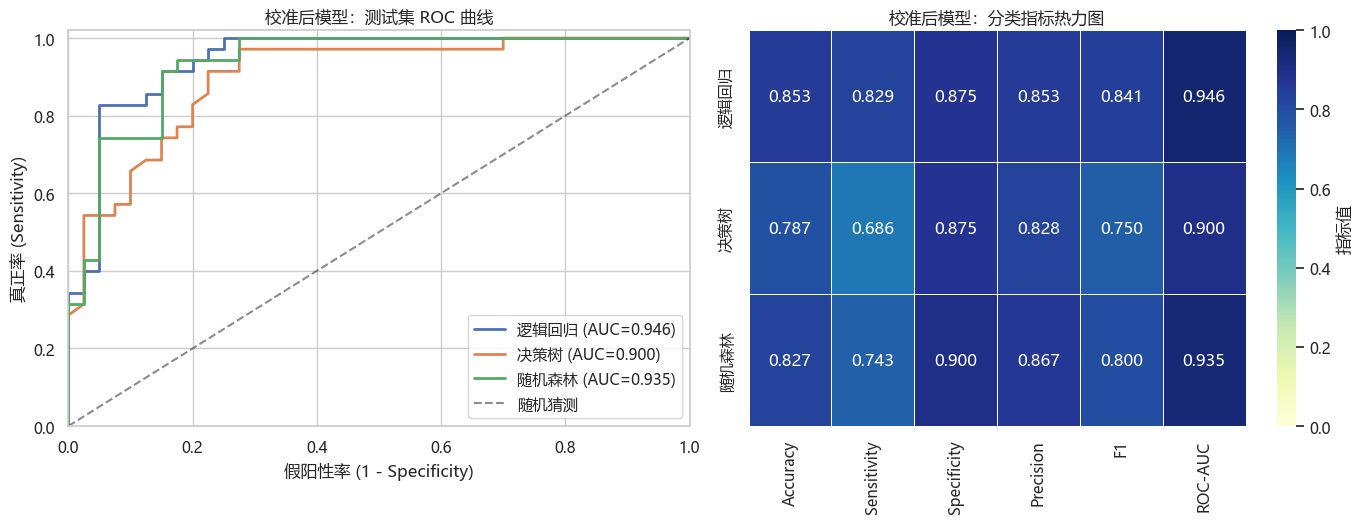

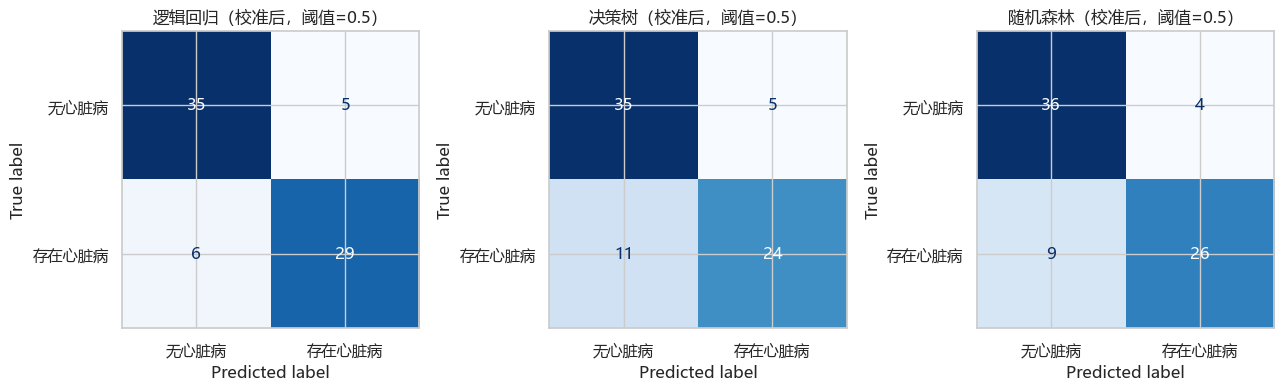

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.4))
for name, (fpr, tpr, _) in roc_data.items():
    axes[0].plot(fpr, tpr, linewidth=2,
                 label=f"{name} (AUC={metrics_df.loc[name, 'ROC-AUC']:.3f})")
axes[0].plot([0, 1], [0, 1], "k--", alpha=0.5, label="随机猜测")
axes[0].set(xlabel="假阳性率 (1 - Specificity)", ylabel="真正率 (Sensitivity)",
            title="校准后模型：测试集 ROC 曲线", xlim=(0, 1), ylim=(0, 1.02))
axes[0].legend(loc="lower right")

metric_columns = ["Accuracy", "Sensitivity", "Specificity", "Precision", "F1", "ROC-AUC"]
sns.heatmap(metrics_df[metric_columns].astype(float), annot=True, fmt=".3f",
            cmap="YlGnBu", vmin=0, vmax=1, linewidths=0.5,
            cbar_kws={"label": "指标值"}, ax=axes[1])
axes[1].set_title("校准后模型：分类指标热力图")
axes[1].set_xlabel("")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, (name, matrix) in zip(axes, confusions.items()):
    ConfusionMatrixDisplay(matrix, display_labels=["无心脏病", "存在心脏病"]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d"
    )
    ax.set_title(f"{name}（校准后，阈值=0.5）")
plt.tight_layout()
plt.show()

### 4.1 校准曲线、概率分布与概率质量对比

校准曲线越接近对角线，表示预测概率越接近实际患病频率。下方同时展示校准前后的曲线与概率分布，并用统一尺度的 Brier 分数和 LogLoss 比较改进幅度。

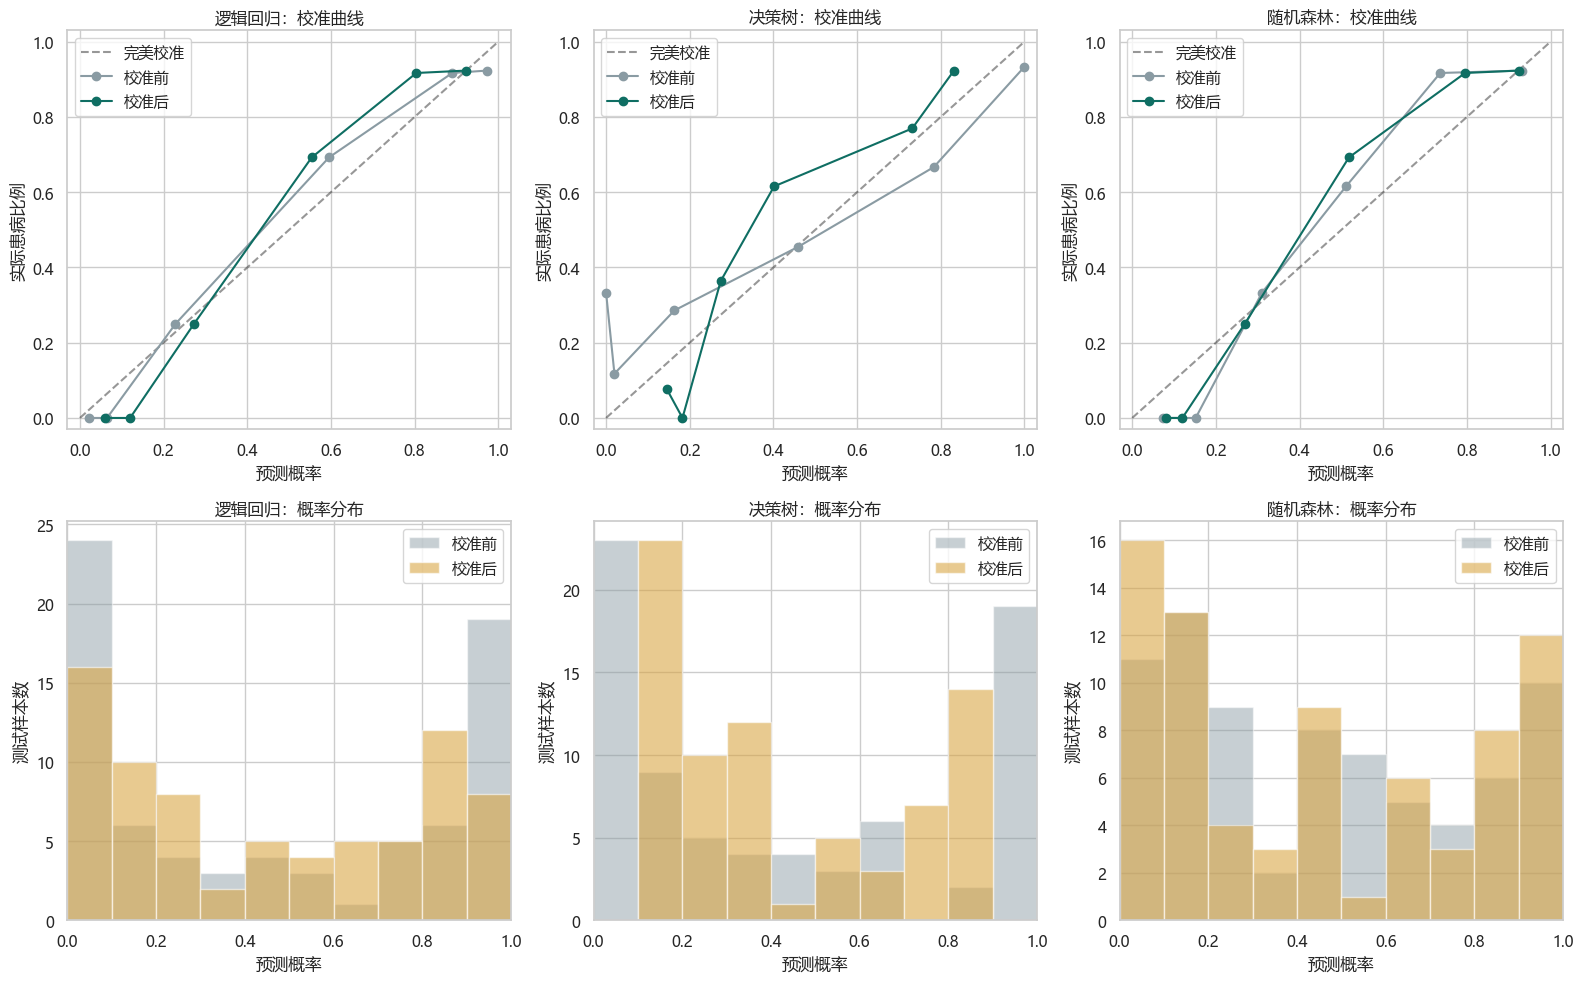

,模型,指标,校准前,校准后,变化,相对改善(%)
0,逻辑回归,Brier分数,0.091,0.096,0.005,-5.391
1,逻辑回归,LogLoss,0.299,0.322,0.024,-7.972
2,决策树,Brier分数,0.180,0.144,-0.036,19.997
3,决策树,LogLoss,1.819,0.450,-1.369,75.253
4,随机森林,Brier分数,0.112,0.107,-0.005,4.649
5,随机森林,LogLoss,0.362,0.350,-0.011,3.110


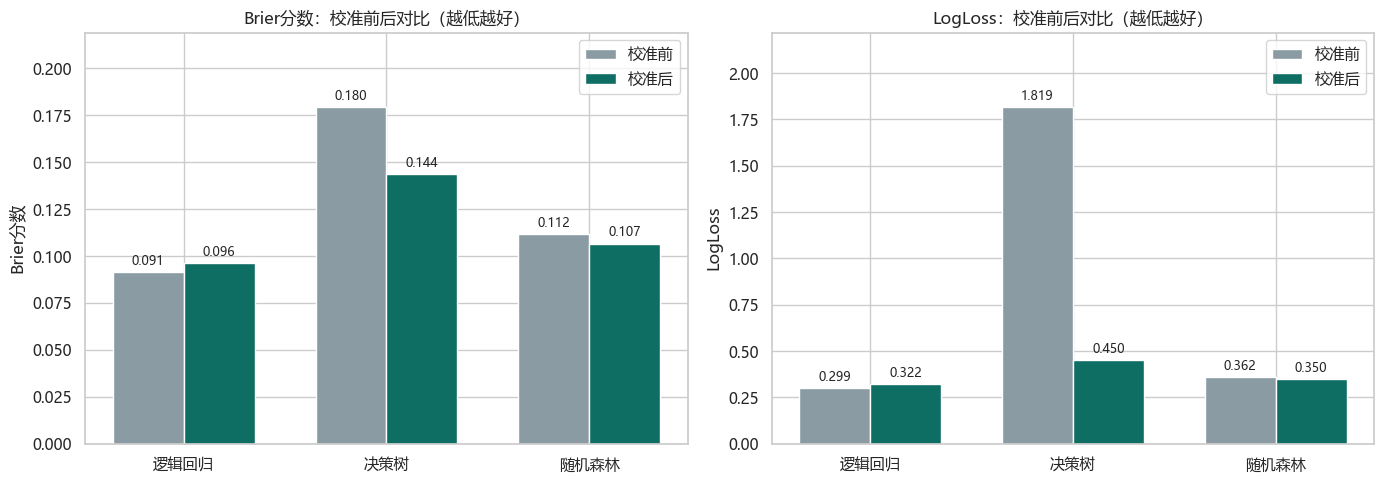

In [8]:
from sklearn.calibration import calibration_curve

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for column, name in enumerate(models):
    ax = axes[0, column]
    ax.plot([0, 1], [0, 1], "k--", alpha=0.45, label="完美校准")
    for probability, label, color in [
        (baseline_probabilities[name], "校准前", "#8A9BA3"),
        (calibrated_probabilities[name], "校准后", "#0F6E63"),
    ]:
        fraction_positive, mean_predicted = calibration_curve(
            y_test, probability, n_bins=6, strategy="quantile"
        )
        ax.plot(mean_predicted, fraction_positive, "o-", label=label, color=color)
    ax.set(xlabel="预测概率", ylabel="实际患病比例", title=f"{name}：校准曲线",
           xlim=(-0.03, 1.03), ylim=(-0.03, 1.03))
    ax.legend()

    ax = axes[1, column]
    bins = np.linspace(0, 1, 11)
    ax.hist(baseline_probabilities[name], bins=bins, alpha=0.48,
            label="校准前", color="#8A9BA3", edgecolor="white")
    ax.hist(calibrated_probabilities[name], bins=bins, alpha=0.58,
            label="校准后", color="#D9A441", edgecolor="white")
    ax.set(xlabel="预测概率", ylabel="测试样本数", title=f"{name}：概率分布", xlim=(0, 1))
    ax.legend()
plt.tight_layout()
plt.show()

quality_rows = []
for name in models:
    for metric in ["Brier分数", "LogLoss"]:
        before = baseline_metrics_df.loc[name, metric]
        after = metrics_df.loc[name, metric]
        quality_rows.append({
            "模型": name, "指标": metric, "校准前": before, "校准后": after,
            "变化": after - before,
            "相对改善(%)": (before - after) / before * 100 if before else np.nan,
        })
quality_df = pd.DataFrame(quality_rows)
display(quality_df.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
x = np.arange(len(models))
width = 0.35
for ax, metric in zip(axes, ["Brier分数", "LogLoss"]):
    before_values = baseline_metrics_df[metric].values
    after_values = metrics_df[metric].values
    before_bars = ax.bar(x - width / 2, before_values, width, label="校准前", color="#8A9BA3")
    after_bars = ax.bar(x + width / 2, after_values, width, label="校准后", color="#0F6E63")
    ax.set_xticks(x, models.keys())
    ax.set_title(f"{metric}：校准前后对比（越低越好）")
    ax.set_ylabel(metric)
    ax.legend()
    ax.bar_label(before_bars, fmt="%.3f", padding=3, fontsize=9)
    ax.bar_label(after_bars, fmt="%.3f", padding=3, fontsize=9)
    ax.set_ylim(0, max(before_values.max(), after_values.max()) * 1.22)
plt.tight_layout()
plt.show()

分歧样本真实标签：0（无心脏病）


,校准前概率,校准后概率
模型,,
逻辑回归,0.153,0.215
决策树,0.700,0.367
随机森林,0.543,0.495


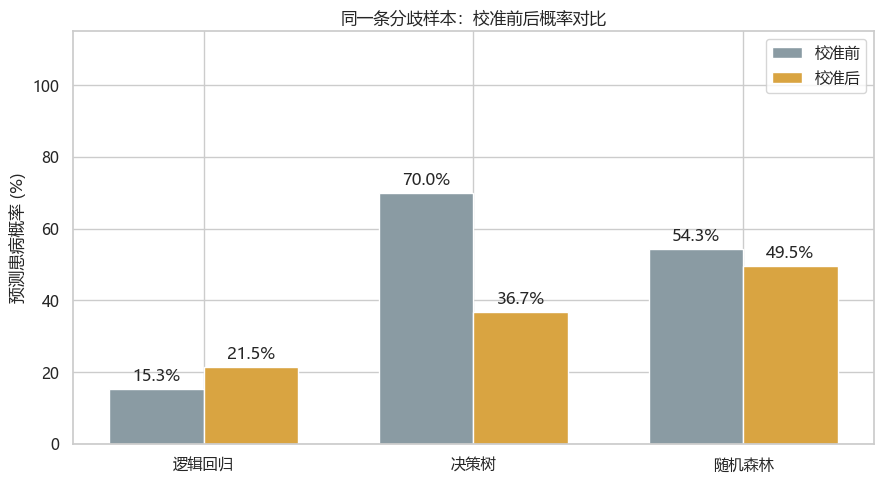

In [9]:
sample = pd.DataFrame([disagreement_example], columns=feature_names)
sample_rows = []
for name in models:
    before = float(uncalibrated_models[name].predict_proba(sample)[0, 1])
    after = float(models[name].predict_proba(sample)[0, 1])
    sample_rows.append({"模型": name, "校准前概率": before, "校准后概率": after})
sample_probability_df = pd.DataFrame(sample_rows).set_index("模型")
print(f"分歧样本真实标签：{disagreement_actual}（无心脏病）")
display(sample_probability_df.round(3))

fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(models))
width = 0.35
before_bars = ax.bar(x - width / 2, sample_probability_df["校准前概率"] * 100,
                     width, label="校准前", color="#8A9BA3")
after_bars = ax.bar(x + width / 2, sample_probability_df["校准后概率"] * 100,
                    width, label="校准后", color="#D9A441")
ax.set_xticks(x, models.keys())
ax.set_ylim(0, 115)
ax.set_ylabel("预测患病概率 (%)")
ax.set_title("同一条分歧样本：校准前后概率对比")
ax.legend()
ax.bar_label(before_bars, fmt="%.1f%%", padding=3)
ax.bar_label(after_bars, fmt="%.1f%%", padding=3)
plt.tight_layout()
plt.show()

### 4.2 使用训练集折外预测寻找最优阈值

默认阈值 0.5 用于与原始实验保持一致，但不一定是每个模型的最佳分类切点。03 版新增模型级阈值搜索：

- 仅在**训练集**上进行 5 折分层交叉验证，使用折外预测概率搜索 0.05～0.95 的阈值；
- 校准模型在每个外层训练折内重新完成 Platt 校准，测试集不参与阈值选择；
- 支持三种规则：**Youden J 最大**（Sensitivity + Specificity − 1）、**F1 最大**、以及 **Sensitivity 至少 0.85 时 Specificity 最大**；
- 最优阈值确定后，再一次性应用到测试集和交互面板，避免用测试集反向调参。

In [10]:
from sklearn.model_selection import cross_val_predict

threshold_candidates = np.round(np.arange(0.05, 0.951, 0.01), 2)
criterion_labels = {
    "youden": "Youden J 最大",
    "f1": "F1 最大",
    "sensitivity": "Sensitivity≥0.85 时 Specificity 最大",
}


def threshold_metrics(y_true, probability, threshold):
    prediction = (probability >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, prediction, labels=[0, 1]).ravel()
    sensitivity = tp / (tp + fn) if tp + fn else np.nan
    specificity = tn / (tn + fp) if tn + fp else np.nan
    return {
        "阈值": threshold,
        "Accuracy": accuracy_score(y_true, prediction),
        "Sensitivity": sensitivity,
        "Specificity": specificity,
        "Precision": precision_score(y_true, prediction, zero_division=0),
        "F1": f1_score(y_true, prediction, zero_division=0),
        "YoudenJ": sensitivity + specificity - 1,
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
    }


def find_optimal_threshold(y_true, probability, criterion="youden", min_sensitivity=0.85):
    rows = [threshold_metrics(y_true, probability, t) for t in threshold_candidates]
    table = pd.DataFrame(rows)
    table["距离0.5"] = (table["阈值"] - 0.5).abs()
    if criterion == "youden":
        ranked = table.sort_values(["YoudenJ", "Specificity", "距离0.5", "阈值"],
                                   ascending=[False, False, True, True])
    elif criterion == "f1":
        ranked = table.sort_values(["F1", "YoudenJ", "距离0.5", "阈值"],
                                   ascending=[False, False, True, True])
    elif criterion == "sensitivity":
        eligible = table[table["Sensitivity"] >= min_sensitivity]
        if eligible.empty:
            raise ValueError(f"没有阈值能使 Sensitivity 达到 {min_sensitivity:.0%}")
        ranked = eligible.sort_values(["Specificity", "YoudenJ", "距离0.5", "阈值"],
                                      ascending=[False, False, True, True])
    else:
        raise ValueError("criterion 必须是 youden、f1 或 sensitivity")
    return float(ranked.iloc[0]["阈值"]), table


oof_probabilities = {}
threshold_tables = {}
optimal_thresholds = {}
optimal_rows = []
for name, model in models.items():
    oof_probability = cross_val_predict(
        model, X_train, y_train, cv=cv, method="predict_proba"
    )[:, 1]
    oof_probabilities[name] = oof_probability
    optimal_thresholds[name] = {}
    for criterion in criterion_labels:
        best_threshold, table = find_optimal_threshold(y_train, oof_probability, criterion)
        threshold_tables[name] = table
        optimal_thresholds[name][criterion] = best_threshold
        best_row = table[np.isclose(table["阈值"], best_threshold)].iloc[0]
        optimal_rows.append({
            "模型": name,
            "选择规则": criterion_labels[criterion],
            "最优阈值": best_threshold,
            "折外Accuracy": best_row["Accuracy"],
            "折外Sensitivity": best_row["Sensitivity"],
            "折外Specificity": best_row["Specificity"],
            "折外F1": best_row["F1"],
            "折外YoudenJ": best_row["YoudenJ"],
        })

optimal_threshold_df = pd.DataFrame(optimal_rows)
display(optimal_threshold_df.round(3))

threshold_test_rows = []
for name in models:
    probability = calibrated_probabilities[name]
    for scheme, threshold in [
        ("默认阈值0.5", 0.5),
        ("训练集Youden最优阈值", optimal_thresholds[name]["youden"]),
    ]:
        threshold_test_rows.append({
            "模型": name, "方案": scheme, "阈值": threshold,
            **threshold_metrics(y_test, probability, threshold),
        })
threshold_test_df = pd.DataFrame(threshold_test_rows)
print("将训练集选出的 Youden 最优阈值应用到测试集：")
display(threshold_test_df[["模型", "方案", "阈值", "Accuracy", "Sensitivity", "Specificity", "Precision", "F1", "YoudenJ"]].round(3))

,模型,选择规则,最优阈值,折外Accuracy,折外Sensitivity,折外Specificity,折外F1,折外YoudenJ
0,逻辑回归,Youden J 最大,0.46,0.833,0.814,0.850,0.818,0.664
1,逻辑回归,F1 最大,0.46,0.833,0.814,0.850,0.818,0.664
2,逻辑回归,Sensitivity≥0.85 时 Specificity 最大,0.35,0.788,0.863,0.725,0.789,0.588
3,决策树,Youden J 最大,0.51,0.847,0.784,0.900,0.825,0.684
4,决策树,F1 最大,0.51,0.847,0.784,0.900,0.825,0.684
5,决策树,Sensitivity≥0.85 时 Specificity 最大,0.30,0.739,0.853,0.642,0.750,0.495
6,随机森林,Youden J 最大,0.54,0.851,0.765,0.925,0.825,0.690
7,随机森林,F1 最大,0.54,0.851,0.765,0.925,0.825,0.690
8,随机森林,Sensitivity≥0.85 时 Specificity 最大,0.34,0.797,0.853,0.750,0.795,0.603


将训练集选出的 Youden 最优阈值应用到测试集：


,模型,方案,阈值,Accuracy,Sensitivity,Specificity,Precision,F1,YoudenJ
0,逻辑回归,默认阈值0.5,0.50,0.853,0.829,0.875,0.853,0.841,0.704
1,逻辑回归,训练集Youden最优阈值,0.46,0.867,0.857,0.875,0.857,0.857,0.732
2,决策树,默认阈值0.5,0.50,0.787,0.686,0.875,0.828,0.750,0.561
3,决策树,训练集Youden最优阈值,0.51,0.787,0.657,0.900,0.852,0.742,0.557
4,随机森林,默认阈值0.5,0.50,0.827,0.743,0.900,0.867,0.800,0.643
5,随机森林,训练集Youden最优阈值,0.54,0.840,0.743,0.925,0.897,0.812,0.668


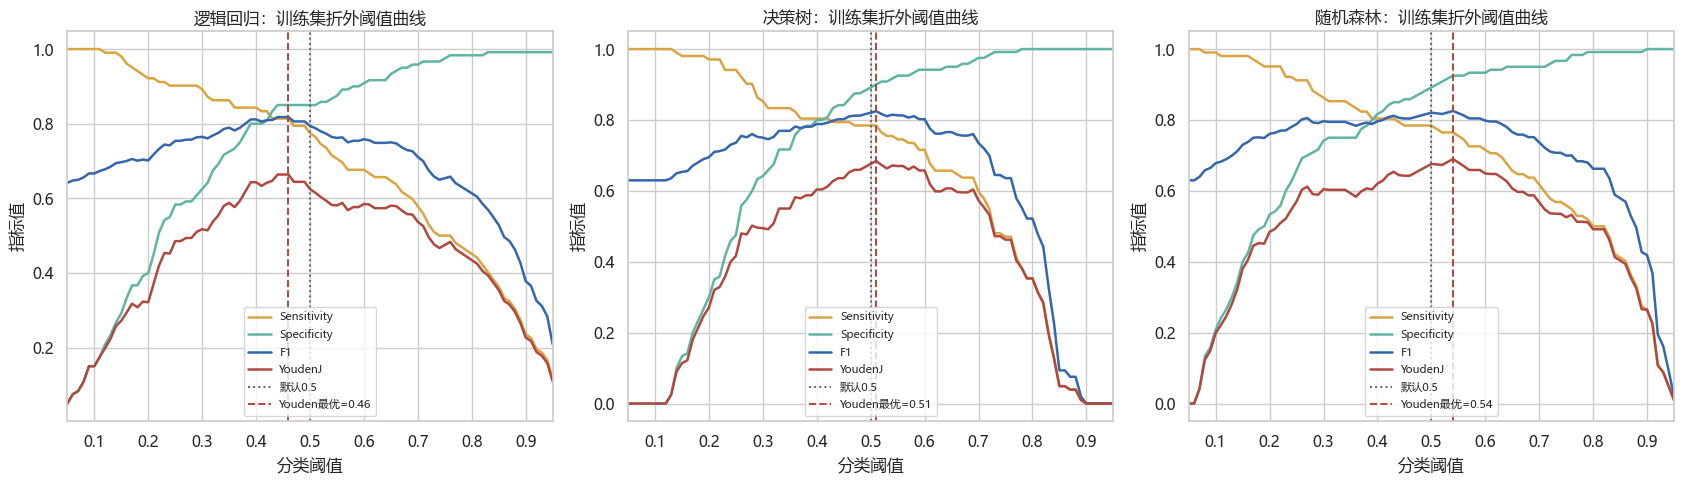

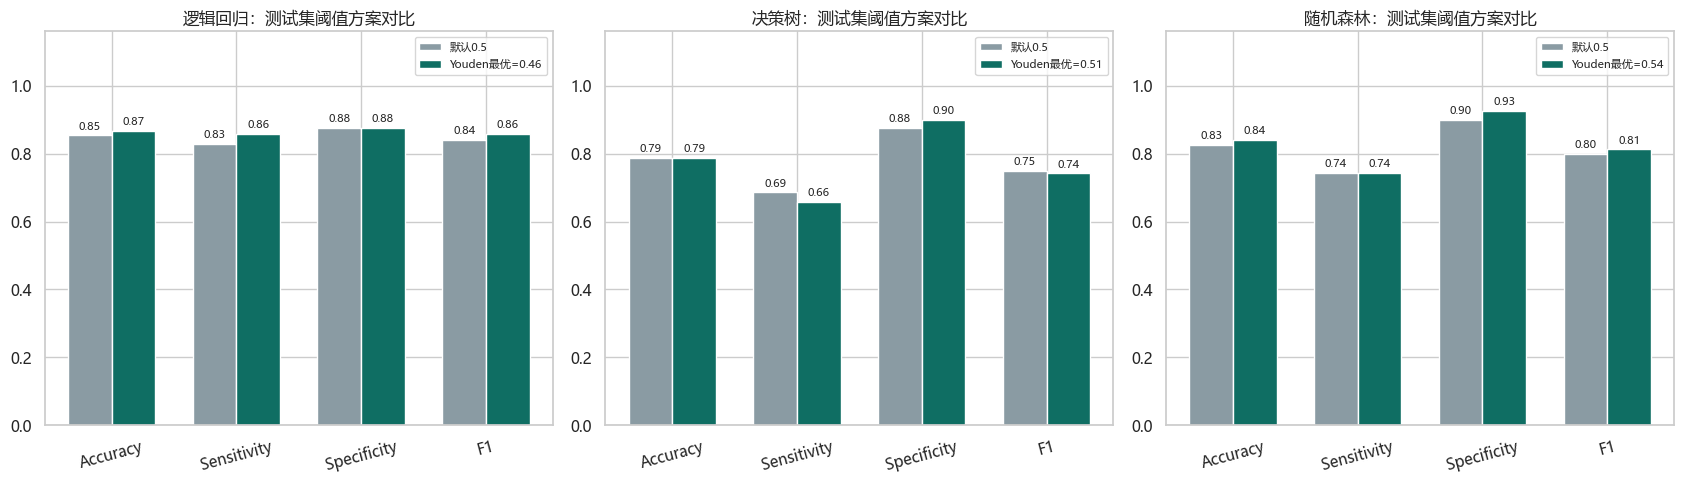

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, name in zip(axes, models):
    table = threshold_tables[name]
    for column, color in [
        ("Sensitivity", "#D9A441"),
        ("Specificity", "#5FB4A5"),
        ("F1", "#3366AA"),
        ("YoudenJ", "#B0483E"),
    ]:
        ax.plot(table["阈值"], table[column], label=column, color=color, linewidth=1.8)
    best_threshold = optimal_thresholds[name]["youden"]
    ax.axvline(0.5, color="#59666C", linestyle=":", linewidth=1.4, label="默认0.5")
    ax.axvline(best_threshold, color="#B0483E", linestyle="--", linewidth=1.4,
               label=f"Youden最优={best_threshold:.2f}")
    ax.set(xlabel="分类阈值", ylabel="指标值", title=f"{name}：训练集折外阈值曲线", xlim=(0.05, 0.95))
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
comparison_metrics = ["Accuracy", "Sensitivity", "Specificity", "F1"]
x = np.arange(len(comparison_metrics))
width = 0.35
for ax, name in zip(axes, models):
    subset = threshold_test_df[threshold_test_df["模型"] == name].set_index("方案")
    default_values = subset.loc["默认阈值0.5", comparison_metrics].astype(float).values
    optimal_values = subset.loc["训练集Youden最优阈值", comparison_metrics].astype(float).values
    default_bars = ax.bar(x - width / 2, default_values, width, label="默认0.5", color="#8A9BA3")
    optimal_bars = ax.bar(x + width / 2, optimal_values, width,
                          label=f"Youden最优={optimal_thresholds[name]['youden']:.2f}", color="#0F6E63")
    ax.set_xticks(x, comparison_metrics, rotation=15)
    ax.set_ylim(0, 1.16)
    ax.set_title(f"{name}：测试集阈值方案对比")
    ax.legend(fontsize=8)
    ax.bar_label(default_bars, fmt="%.2f", padding=2, fontsize=8)
    ax.bar_label(optimal_bars, fmt="%.2f", padding=2, fontsize=8)
plt.tight_layout()
plt.show()

## 5. 特征重要性与医学解释

以下使用测试集上的 **置换重要性（Permutation Importance）**：随机打乱某个特征后 ROC-AUC 平均下降越多，说明该特征对当前模型越重要。它不表示因果关系。逻辑回归部分使用未校准基础模型给出标准化系数方向：正值倾向于提高风险，负值倾向于降低风险。

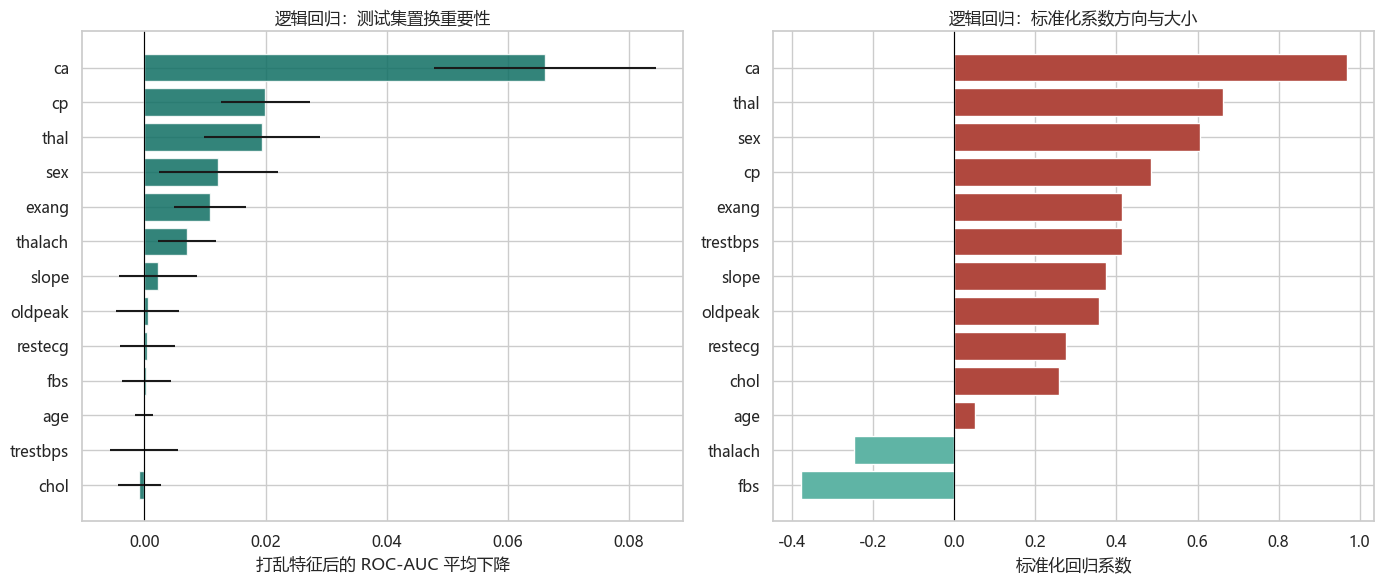

,特征,标准化系数,比值比(每增加1个标准差)
11,ca,0.968,2.633
12,thal,0.664,1.942
1,sex,0.606,1.833
2,cp,0.485,1.625
8,exang,0.415,1.514
3,trestbps,0.413,1.511
10,slope,0.375,1.454
9,oldpeak,0.356,1.428
6,restecg,0.276,1.317
4,chol,0.258,1.294


In [12]:
importance = permutation_importance(
    models[best_model_name], X_test, y_test,
    scoring="roc_auc", n_repeats=30, random_state=RANDOM_STATE
)
importance_df = pd.DataFrame({
    "特征": feature_names,
    "AUC平均下降": importance.importances_mean,
    "标准差": importance.importances_std,
}).sort_values("AUC平均下降", ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].barh(importance_df["特征"], importance_df["AUC平均下降"],
             xerr=importance_df["标准差"], color="#0F6E63", alpha=0.85)
axes[0].axvline(0, color="black", linewidth=0.8)
axes[0].set_title(f"{best_model_name}：测试集置换重要性")
axes[0].set_xlabel("打乱特征后的 ROC-AUC 平均下降")

lr = uncalibrated_models["逻辑回归"].named_steps["classifier"]
coefficient_df = pd.DataFrame({
    "特征": feature_names,
    "标准化系数": lr.coef_[0],
}).sort_values("标准化系数")
coefficient_df["比值比(每增加1个标准差)"] = np.exp(coefficient_df["标准化系数"])
colors = ["#B0483E" if v > 0 else "#5FB4A5" for v in coefficient_df["标准化系数"]]
axes[1].barh(coefficient_df["特征"], coefficient_df["标准化系数"], color=colors)
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set_title("逻辑回归：标准化系数方向与大小")
axes[1].set_xlabel("标准化回归系数")
plt.tight_layout()
plt.show()
display(coefficient_df.sort_values("标准化系数", ascending=False).round(3))

## 6. 动态输入新数据并现场预测

03 版交互面板继续使用 **Platt 校准后的三个模型**，并新增“**采用最优阈值**”功能：

- 选择 Youden J、F1 或“Sensitivity 至少 0.85”规则，再点击“采用最优阈值”，即可使用当前模型在训练集折外预测上找到的阈值；
- 默认阈值仍为 0.5，便于与原始实验对照；
- 点击“低风险示例”“高风险示例”或“分歧样本”可一键填入完整病例；
- 默认修改后自动预测，关闭自动模式后可批量修改，再点击“立即预测”；
- 使用轻量 HTML 概率条，避免 `tight_layout` 警告和重复绘图开销。

各模型概率均已做 **Platt 校准（5 折交叉验证）**。最优阈值仅由训练集确定，但在外部新数据上的表现仍可能变化；概率和分类结果仅供教学演示，不构成医学诊断。

In [13]:
import ipywidgets as widgets
from IPython.display import clear_output

widget_layout = widgets.Layout(width="305px")
style = {"description_width": "initial"}

inputs = {
    "age": widgets.BoundedIntText(value=54, min=1, max=120,
                                  description="年龄 age（岁）", layout=widget_layout, style=style),
    "sex": widgets.Dropdown(options=[("女", 0), ("男", 1)], value=1,
                            description="性别 sex", layout=widget_layout, style=style),
    "cp": widgets.Dropdown(options=[("1 典型心绞痛", 1), ("2 非典型心绞痛", 2),
                                    ("3 非心绞痛性疼痛", 3), ("4 无症状", 4)], value=4,
                           description="胸痛类型 cp", layout=widget_layout, style=style),
    "trestbps": widgets.BoundedIntText(value=130, min=60, max=260,
                                       description="静息血压 trestbps（mmHg）", layout=widget_layout, style=style),
    "chol": widgets.BoundedIntText(value=246, min=80, max=700,
                                   description="胆固醇 chol（mg/dl）", layout=widget_layout, style=style),
    "fbs": widgets.Dropdown(options=[("否（≤120）", 0), ("是（>120）", 1)], value=0,
                            description="空腹血糖 fbs", layout=widget_layout, style=style),
    "restecg": widgets.Dropdown(options=[("0 正常", 0), ("1 ST-T 波异常", 1),
                                         ("2 左心室肥大", 2)], value=0,
                                description="静息心电图 restecg", layout=widget_layout, style=style),
    "thalach": widgets.BoundedIntText(value=150, min=40, max=260,
                                      description="最大心率 thalach（次/分）", layout=widget_layout, style=style),
    "exang": widgets.Dropdown(options=[("否", 0), ("是", 1)], value=0,
                              description="运动诱发心绞痛 exang", layout=widget_layout, style=style),
    "oldpeak": widgets.BoundedFloatText(value=1.0, min=0, max=10, step=0.1,
                                        description="ST 段压低 oldpeak", layout=widget_layout, style=style),
    "slope": widgets.Dropdown(options=[("1 上升", 1), ("2 平坦", 2), ("3 下降", 3)], value=2,
                              description="ST 段斜率 slope", layout=widget_layout, style=style),
    "ca": widgets.Dropdown(options=[0, 1, 2, 3], value=0,
                           description="主要血管数 ca", layout=widget_layout, style=style),
    "thal": widgets.Dropdown(options=[("3 正常", 3), ("6 固定缺陷", 6),
                                      ("7 可逆缺陷", 7)], value=3,
                             description="地中海贫血类型 thal", layout=widget_layout, style=style),
}

default_values = {name: control.value for name, control in inputs.items()}
low_risk_example = {
    "age": 35, "sex": 0, "cp": 3, "trestbps": 110, "chol": 180,
    "fbs": 0, "restecg": 0, "thalach": 180, "exang": 0,
    "oldpeak": 0.0, "slope": 1, "ca": 0, "thal": 3,
}
high_risk_example = {
    "age": 67, "sex": 1, "cp": 4, "trestbps": 160, "chol": 286,
    "fbs": 0, "restecg": 2, "thalach": 108, "exang": 1,
    "oldpeak": 1.5, "slope": 2, "ca": 3, "thal": 3,
}

model_picker = widgets.ToggleButtons(
    options=list(models.keys()), value="逻辑回归", description="预测模型",
    style={"description_width": "initial", "button_width": "100px"},
    layout=widgets.Layout(width="430px")
)
threshold_widget = widgets.FloatSlider(
    value=0.50, min=0.05, max=0.95, step=0.01, description="高风险阈值",
    continuous_update=False, readout_format=".2f",
    layout=widgets.Layout(width="430px"), style={"description_width": "initial"}
)
auto_widget = widgets.Checkbox(value=True, description="修改后自动预测", indent=False)
criterion_widget = widgets.Dropdown(
    options=[("Youden J 最大", "youden"), ("F1 最大", "f1"),
             ("Sensitivity≥0.85 时 Specificity 最大", "sensitivity")],
    value="youden", description="阈值规则", layout=widget_layout, style=style
)
optimal_button = widgets.Button(description="采用最优阈值", button_style="success", icon="line-chart")
predict_button = widgets.Button(description="立即预测", button_style="primary", icon="play")
low_button = widgets.Button(description="低风险示例", icon="user")
high_button = widgets.Button(description="高风险示例", icon="user-md")
reset_button = widgets.Button(description="恢复默认", icon="refresh")
disagreement_button = widgets.Button(description="分歧样本", icon="balance-scale")
prediction_area = widgets.Output()
updating_presets = False


def predict_new_data(model_name, threshold, **values):
    if model_name not in models:
        raise ValueError("请选择有效的预测模型。")
    if not 0 < threshold < 1:
        raise ValueError("分类阈值必须在 0 和 1 之间。")
    if set(values) != set(feature_names):
        raise ValueError("输入字段不完整，请检查 13 项医学指标。")
    new_data = pd.DataFrame([values], columns=feature_names)
    if new_data.isna().any().any():
        raise ValueError("所有输入均须为有效数值，不能留空。")
    probability = float(models[model_name].predict_proba(new_data)[0, 1])
    prediction = int(probability >= threshold)
    return probability, prediction, new_data


def render_prediction(*_):
    if updating_presets:
        return
    values = {name: control.value for name, control in inputs.items()}
    with prediction_area:
        clear_output(wait=True)
        try:
            probability, prediction, new_data = predict_new_data(
                model_picker.value, threshold_widget.value, **values
            )
        except (ValueError, TypeError) as error:
            display(HTML(f'<div style="color:#B0483E"><b>无法预测：</b>{error}</div>'))
            return
        label = "高风险（1）" if prediction == 1 else "较低风险（0）"
        color = "#B0483E" if prediction == 1 else "#0F6E63"
        percent = probability * 100
        threshold_percent = threshold_widget.value * 100
        display(HTML(f"""
            <div style="border-left:6px solid {color};padding:10px 14px;margin:8px 0;background:#f6f8f9;max-width:920px">
              <div style="font-size:18px"><b>模型分类：{label}</b></div>
              <div>模型：<b>{model_picker.value}</b>　校准后心脏病概率：<b style="color:{color};font-size:20px">{probability:.1%}</b>　阈值：{threshold_widget.value:.2f}</div>
              <div style="position:relative;height:20px;background:#E4E9EC;border-radius:5px;margin-top:10px">
                <div style="width:{percent:.2f}%;height:20px;background:{color};border-radius:5px"></div>
                <div style="position:absolute;left:{threshold_percent:.2f}%;top:-3px;height:26px;border-left:2px dashed #22333B"></div>
              </div>
              <div style="display:flex;justify-content:space-between;color:#59666c;font-size:12px"><span>0%</span><span>虚线为分类阈值</span><span>100%</span></div>
            </div>
        """))
        record = "　".join(f"<span style='white-space:nowrap'><b>{col}</b>={new_data.iloc[0][col]}</span>" for col in feature_names)
        display(HTML(f"<details style='max-width:920px'><summary>查看本次输入记录</summary><div style='line-height:1.9;margin-top:6px'>{record}</div></details>"))
        display(HTML('<div style="color:#59666c;margin-top:5px">仅供课程演示，不构成医学诊断。</div>'))


def apply_preset(values):
    global updating_presets
    updating_presets = True
    try:
        for name, value in values.items():
            inputs[name].value = value
    finally:
        updating_presets = False
    render_prediction()


def reset_panel(_):
    global updating_presets
    updating_presets = True
    try:
        for name, value in default_values.items():
            inputs[name].value = value
        model_picker.value = "逻辑回归"
        threshold_widget.value = 0.50
    finally:
        updating_presets = False
    render_prediction()


def use_optimal_threshold(_):
    threshold_widget.value = optimal_thresholds[model_picker.value][criterion_widget.value]
    render_prediction()


def on_input_change(change):
    if auto_widget.value:
        render_prediction()


def on_auto_change(change):
    if change["new"]:
        render_prediction()


for control in inputs.values():
    control.observe(on_input_change, names="value")
model_picker.observe(on_input_change, names="value")
threshold_widget.observe(on_input_change, names="value")
auto_widget.observe(on_auto_change, names="value")
predict_button.on_click(render_prediction)
optimal_button.on_click(use_optimal_threshold)
low_button.on_click(lambda _: apply_preset(low_risk_example))
high_button.on_click(lambda _: apply_preset(high_risk_example))
reset_button.on_click(reset_panel)
disagreement_button.on_click(lambda _: apply_preset(disagreement_example))

input_grid = widgets.GridBox(
    children=list(inputs.values()),
    layout=widgets.Layout(grid_template_columns="repeat(3, 305px)", grid_gap="6px 14px")
)
quick_buttons = widgets.HBox(
    [low_button, high_button, disagreement_button, reset_button, predict_button],
    layout=widgets.Layout(flex_flow="row wrap", gap="6px")
)
display(widgets.HTML("""
    <h3>现场预测面板</h3>
    <div>可点击示例快速填入，也可直接修改数值。各模型概率均已做 Platt 校准（5 折交叉验证），用于估计经验患病概率；跨模型比较请结合校准曲线与 Brier 分数。</div>
"""))
display(quick_buttons)
display(widgets.VBox([model_picker, threshold_widget, auto_widget]))
display(widgets.HBox([criterion_widget, optimal_button]))
display(input_grid)
display(prediction_area)
render_prediction()

HTML(value='\n    <h3>现场预测面板</h3>\n    <div>可点击示例快速填入，也可直接修改数值。各模型概率均已做 Platt 校准（5 折交叉验证），用于估计经验患病概率；跨模型比较请结合校…

GridBox(children=(BoundedIntText(value=54, description='年龄 age（岁）', layout=Layout(width='305px'), max=120, min…

Output()

## 7. 结论与使用边界

- 03 版保留 02 版的 Platt 概率校准、Brier/LogLoss 和校准前后可视化，并新增训练集折外最优阈值搜索。
- Youden J、F1 和敏感度约束对应不同目标，不存在适用于所有场景的单一“最佳阈值”。
- 最优阈值由训练集确定，测试集只用于最终评估；外部数据上的阈值表现仍需要独立验证。
- ROC-AUC、Sensitivity 等指标反映区分能力；Brier 分数和 LogLoss 反映概率质量，应结合解读。
- Cleveland 数据仅 297 条完整病例，测试集仅 75 条，校准曲线、阈值和指标均存在抽样波动。
- 类别无序特征当前仍按原方案编码，未来可比较 one-hot 编码；特征重要性不代表病因或治疗建议，本项目不构成医学诊断。